In [3]:
import pandas as pd
import numpy as np
df=pd.read_csv("IN_Trending.csv")
print(df.shape)
df.head()

(3399, 13)


,video_id,trending_date,title,channel_title,views,likes,dislikes,publish_time,category_id,tags,comments,channel_id,description
0,iAtoZar5W58,26.26.02,Aaya Sher - Lyrical | The Paradise | Nani | An...,Saregama Telugu,21242383,836273,0,2026-02-24T14:44:06Z,10,Anirudh Ravichander|The Paradise Theme OST|The...,24917.0,UC68nKdrLbLL0Vj7ilVkLmmg,"For more latest songs & videos, subscribe 👉 ht..."
1,BCQwSlYlEe8,26.26.02,Thaai Kizhavi - Official Trailer | Radikaa Sar...,Saregama Tamil,1913244,43317,0,2026-02-23T11:30:09Z,1,Maatikitaan Minorkunju|Maatikitaan Minorkunju ...,1181.0,UCzee67JnEcuvjErRyWP3GpQ,"For more latest songs & videos, subscribe 👉 ht..."
2,tVDiaaVkfNw,26.26.02,"Minecraft, But Every Mob in Chest!",Carry Depie,463090,9151,0,2026-02-26T09:01:45Z,20,carry depie|minecraft,434.0,UClqifC6Nd7v-IfTqce4k62A,in this video every mob become chest in minecr...
3,DBC2461TQbQ,26.26.02,"#Video - चोली के समान - #Ashish Yadav, Khushi ...",Aashish Yadav Entertainment,699235,60368,0,2026-02-26T00:30:09Z,10,Ashish Yadav|चोली के समान|Khushi Kakkar|ashish...,6468.0,UCjaOWpDTaZKe63ApNJ8BLPg,►Album :- चोली के समान ►Song :- Choli Ke Saman...
4,qj0TyXhGaLw,26.26.02,3000 Crore Plan Dhurandhar 2 Secret Deal | Dee...,Filmi Indian,232987,11738,0,2026-02-25T09:16:32Z,24,dhurandhar 2|dhurandhar 2 trailer|dhurandhar|d...,1065.0,UCeiAKuJGZrIjYvaq0nMwbJg,3000 Crore Plan Dhurandhar 2 Secret Deal Expla...


In [4]:
df.columns

Index(['video_id', 'trending_date', 'title', 'channel_title', 'views', 'likes',
       'dislikes', 'publish_time', 'category_id', 'tags', 'comments',
       'channel_id', 'description'],
      dtype='object')

In [5]:
df.isnull().sum()

,0
video_id,0
trending_date,0
title,0
channel_title,0
views,0
likes,0
dislikes,0
publish_time,0
category_id,0
tags,0


In [7]:
df['description'] = df['description'].fillna('')

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df['video_id'].duplicated().sum()

np.int64(0)

In [10]:
df['publish_time'] = pd.to_datetime(df['publish_time'], errors='coerce', utc=True)

In [11]:
df['publish_time'].dtype

datetime64[ns, UTC]

In [13]:
category_map = {
    1: 'Film & Animation',
    2: 'Autos & Vehicles',
    10: 'Music',
    15: 'Pets & Animals',
    17: 'Sports',
    19: 'Travel & Events',
    20: 'Gaming',
    22: 'People & Blogs',
    23: 'Comedy',
    24: 'Entertainment',
    25: 'News & Politics',
    26: 'Howto & Style',
    27: 'Education',
    28: 'Science & Technology'
}

df['category'] = df['category_id'].map(category_map)

In [14]:
df['category'].value_counts()

,count
category,
Music,1104
Entertainment,803
Gaming,697
People & Blogs,253
Film & Animation,153
News & Politics,136
Comedy,61
Sports,58
Science & Technology,49


In [15]:
category_views = df.groupby('category')['views'].mean().sort_values(ascending=False)

print(category_views)

category
Comedy                  3.719784e+06
Travel & Events         3.101356e+06
Gaming                  2.711211e+06
Howto & Style           2.417729e+06
People & Blogs          2.010870e+06
Film & Animation        1.693312e+06
Science & Technology    1.580337e+06
Autos & Vehicles        1.578535e+06
Music                   1.465110e+06
Education               1.327188e+06
Entertainment           1.284135e+06
Sports                  8.549763e+05
News & Politics         4.839628e+05
Pets & Animals          3.625840e+05
Name: views, dtype: float64


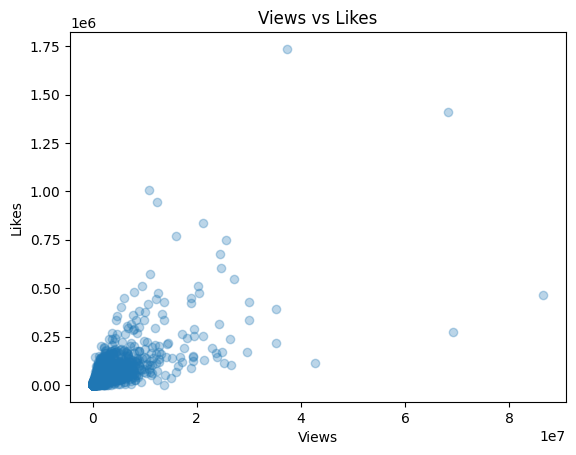

In [16]:
import matplotlib.pyplot as plt

plt.scatter(df['views'], df['likes'], alpha=0.3)
plt.xlabel('Views')
plt.ylabel('Likes')
plt.title('Views vs Likes')
plt.show()

In [18]:
top_channels = df['channel_title'].value_counts().head(10)

print(top_channels)

channel_title
Saregama Telugu                500
Filmi Indian                   500
Carry Depie                    500
Saregama Tamil                 500
Aashish Yadav Entertainment    142
ProBoiz 95                      55
Behindwoods TV                   6
Thanthi TV                       5
Facts In Minutes                 4
PuthiyathalaimuraiTV             4
Name: count, dtype: int64


In [19]:
df['publish_hour'] = df['publish_time'].dt.hour

In [20]:
hour_counts = df['publish_hour'].value_counts().sort_index()

print(hour_counts)

publish_hour
0      70
1      87
2      37
3      51
4     114
5     210
6     134
7     184
8     199
9     263
10    299
11    423
12    495
13    286
14    288
15     81
16     48
17     40
18     38
19     16
20      8
21      6
22     12
23     10
Name: count, dtype: int64


In [21]:
df['engagement_rate'] = np.where(
    df['views'] > 0,
    ((df['likes'] + df['comments']) / df['views']) * 100,
    0
)

In [22]:
df['like_rate'] = np.where(
    df['views'] > 0,
    (df['likes'] / df['views']) * 100,
    0
)

In [23]:
df['comment_rate'] = np.where(
    df['views'] > 0,
    (df['comments'] / df['views']) * 100,
    0
)

In [24]:
df['publish_hour'] = df['publish_time'].dt.hour

In [25]:
df['publish_day'] = df['publish_time'].dt.day_name()

In [26]:
df['publish_month'] = df['publish_time'].dt.month_name()

In [27]:
df['title_length'] = df['title'].str.len()

In [28]:
df['tag_count'] = df['tags'].fillna('').apply(
    lambda x: 0 if x == '[None]' else len(x.split('|'))
)

In [29]:
numeric_cols = [
    'views',
    'likes',
    'comments',
    'engagement_rate',
    'like_rate',
    'comment_rate',
    'title_length',
    'tag_count'
]

correlation = df[numeric_cols].corr()

print(correlation)

                    views     likes  comments  engagement_rate  like_rate  \
views            1.000000  0.685761  0.285361        -0.113897  -0.110590   
likes            0.685761  1.000000  0.550702         0.176379   0.180839   
comments         0.285361  0.550702  1.000000         0.100461   0.076206   
engagement_rate -0.113897  0.176379  0.100461         1.000000   0.995387   
like_rate       -0.110590  0.180839  0.076206         0.995387   1.000000   
comment_rate    -0.071854  0.017181  0.267523         0.388914   0.298729   
title_length    -0.062501 -0.132422 -0.058385        -0.179642  -0.180791   
tag_count       -0.067313 -0.162340 -0.002064        -0.186884  -0.199666   

                 comment_rate  title_length  tag_count  
views               -0.071854     -0.062501  -0.067313  
likes                0.017181     -0.132422  -0.162340  
comments             0.267523     -0.058385  -0.002064  
engagement_rate      0.388914     -0.179642  -0.186884  
like_rate            

In [30]:
df_final = df.copy()

In [31]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3399 entries, 0 to 3398
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype              
---  ------           --------------  -----              
 0   video_id         3399 non-null   object             
 1   trending_date    3399 non-null   object             
 2   title            3399 non-null   object             
 3   channel_title    3399 non-null   object             
 4   views            3399 non-null   int64              
 5   likes            3399 non-null   int64              
 6   dislikes         3399 non-null   int64              
 7   publish_time     3399 non-null   datetime64[ns, UTC]
 8   category_id      3399 non-null   int64              
 9   tags             3399 non-null   object             
 10  comments         3398 non-null   float64            
 11  channel_id       3398 non-null   object             
 12  description      3399 non-null   object             
 13  category         3

In [32]:
df_final.head()

,video_id,trending_date,title,channel_title,views,likes,dislikes,publish_time,category_id,tags,...,description,category,publish_hour,engagement_rate,like_rate,comment_rate,publish_day,publish_month,title_length,tag_count
0,iAtoZar5W58,26.26.02,Aaya Sher - Lyrical | The Paradise | Nani | An...,Saregama Telugu,21242383,836273,0,2026-02-24 14:44:06+00:00,10,Anirudh Ravichander|The Paradise Theme OST|The...,...,"For more latest songs & videos, subscribe 👉 ht...",Music,14,4.054112,3.936813,0.117299,Tuesday,February,80,15
1,BCQwSlYlEe8,26.26.02,Thaai Kizhavi - Official Trailer | Radikaa Sar...,Saregama Tamil,1913244,43317,0,2026-02-23 11:30:09+00:00,1,Maatikitaan Minorkunju|Maatikitaan Minorkunju ...,...,"For more latest songs & videos, subscribe 👉 ht...",Film & Animation,11,2.325788,2.264060,0.061728,Monday,February,95,24
2,tVDiaaVkfNw,26.26.02,"Minecraft, But Every Mob in Chest!",Carry Depie,463090,9151,0,2026-02-26 09:01:45+00:00,20,carry depie|minecraft,...,in this video every mob become chest in minecr...,Gaming,9,2.069792,1.976074,0.093718,Thursday,February,34,2
3,DBC2461TQbQ,26.26.02,"#Video - चोली के समान - #Ashish Yadav, Khushi ...",Aashish Yadav Entertainment,699235,60368,0,2026-02-26 00:30:09+00:00,10,Ashish Yadav|चोली के समान|Khushi Kakkar|ashish...,...,►Album :- चोली के समान ►Song :- Choli Ke Saman...,Music,0,9.558446,8.633435,0.925011,Thursday,February,100,19
4,qj0TyXhGaLw,26.26.02,3000 Crore Plan Dhurandhar 2 Secret Deal | Dee...,Filmi Indian,232987,11738,0,2026-02-25 09:16:32+00:00,24,dhurandhar 2|dhurandhar 2 trailer|dhurandhar|d...,...,3000 Crore Plan Dhurandhar 2 Secret Deal Expla...,Entertainment,9,5.495156,5.038049,0.457107,Wednesday,February,57,25


In [33]:
df_final.to_csv("youtube_trending_cleaned.csv", index=False)